# Objectif 

Analyse de la portion 1 extraite via le code acouplane_select_and_extract_portion1.ipynb

Date de création : 07/10/2026

In [ ]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [ ]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [ ]:
portion_id = 1
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                   ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:50...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 968B 2026-02-25T09:5...
│   │         * src_datetime           (src_datetime) datetime64[ns] 3kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 9kB ...
│   │           atl_lat                (atl_datetime) float64 9kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 509kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 3kB ...
│   │           tir_src_lon            (src_datetime) float64 3kB ...
│   │           tir_src_lat            (src_datetime) float64 3kB ...
│   │           tir_vessel_lon         (src_datetime) float64 3kB ...
│   │           tir_vessel_lat         (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 22kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                   ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:42...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 488B 2026-02-25T00:4...
│   │         * src_datetime           (src_datetime) datetime64[ns] 2kB 2026-02-25T00:42...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 5kB ...
│   │           atl_lat                (atl_datetime) float64 5kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 257kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 2kB ...
│   │           tir_src_lon            (src_datetime) float64 2kB ...
│   │           tir_src_lat            (src_datetime) float64 2kB ...
│   │           tir_vessel_lon         (src_datetime) float64 2kB ...
│   │           tir_vessel_lat         (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 11kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Ouest/Est
│   │           section_id:               1
│   ├── Group: /position/oe2
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

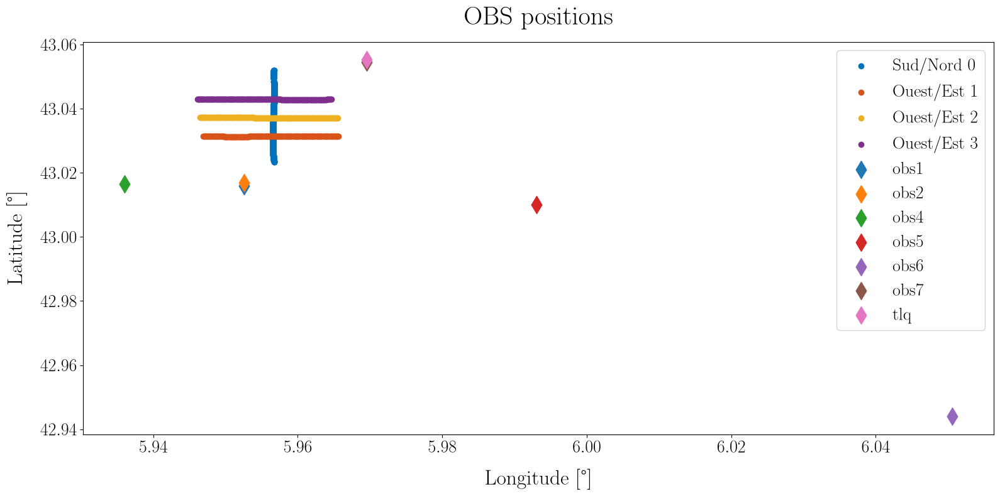

In [ ]:
plot_portion_tir_pos(portion_tree=portion)

# Visualisation des données de pression

## Signaux

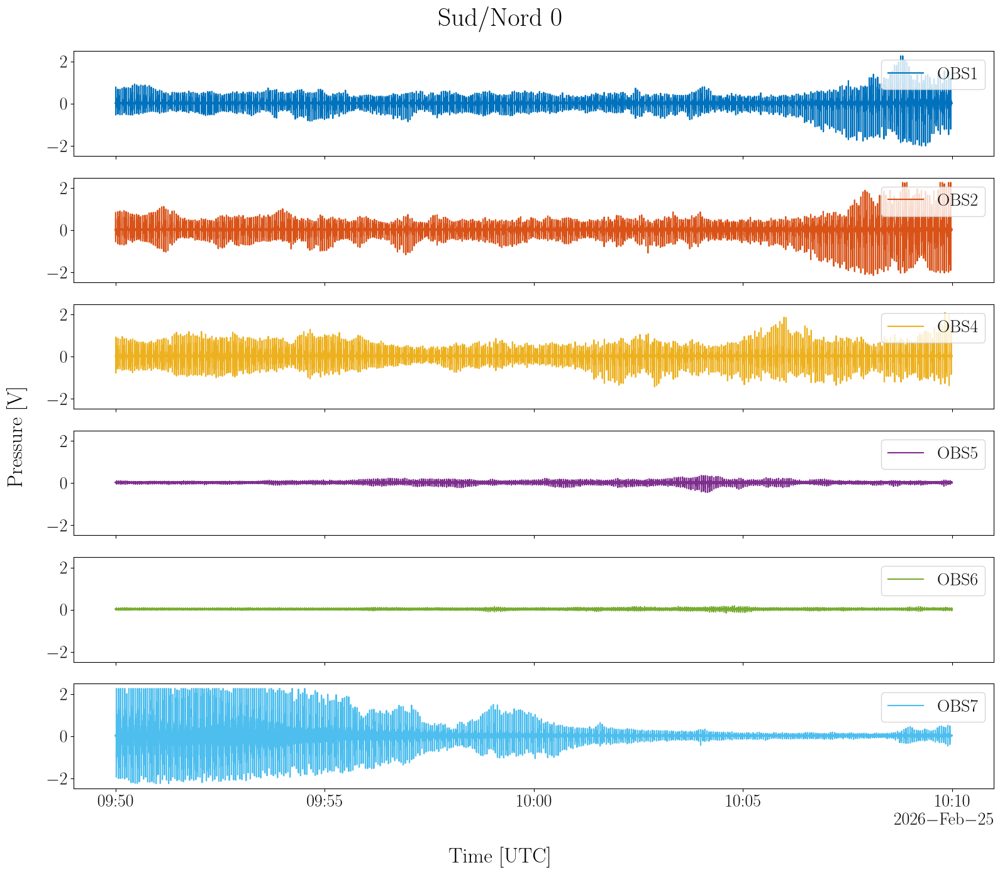

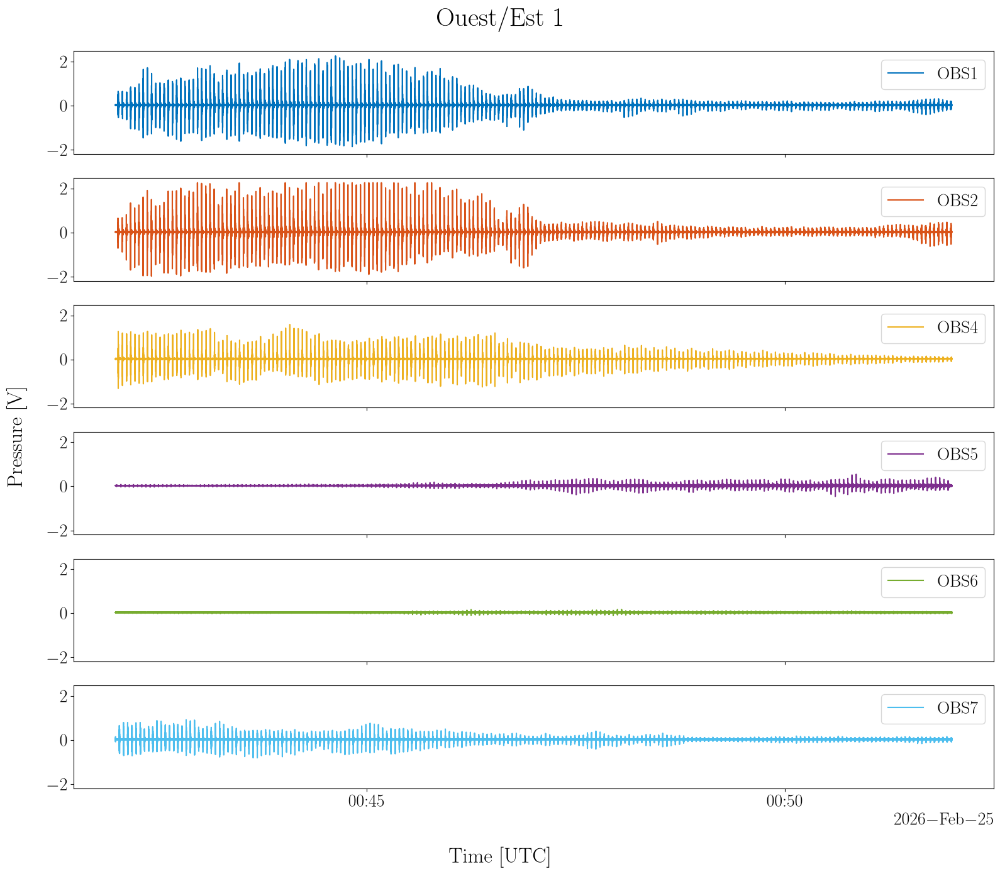

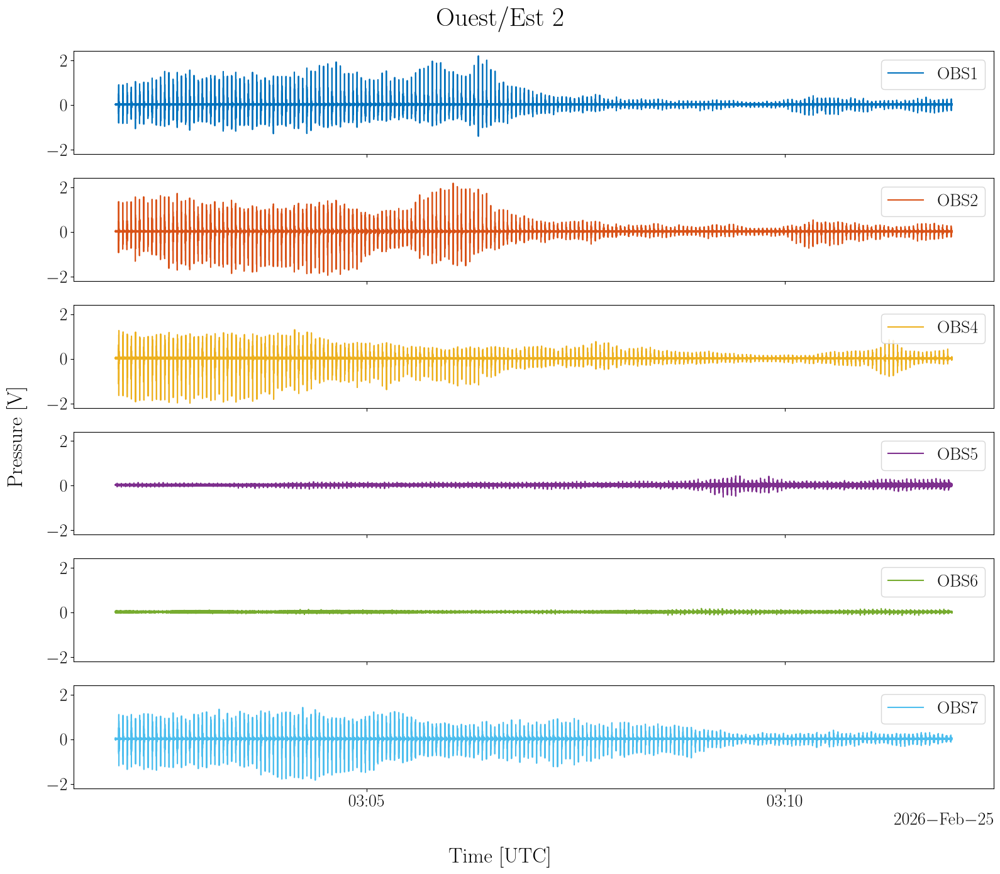

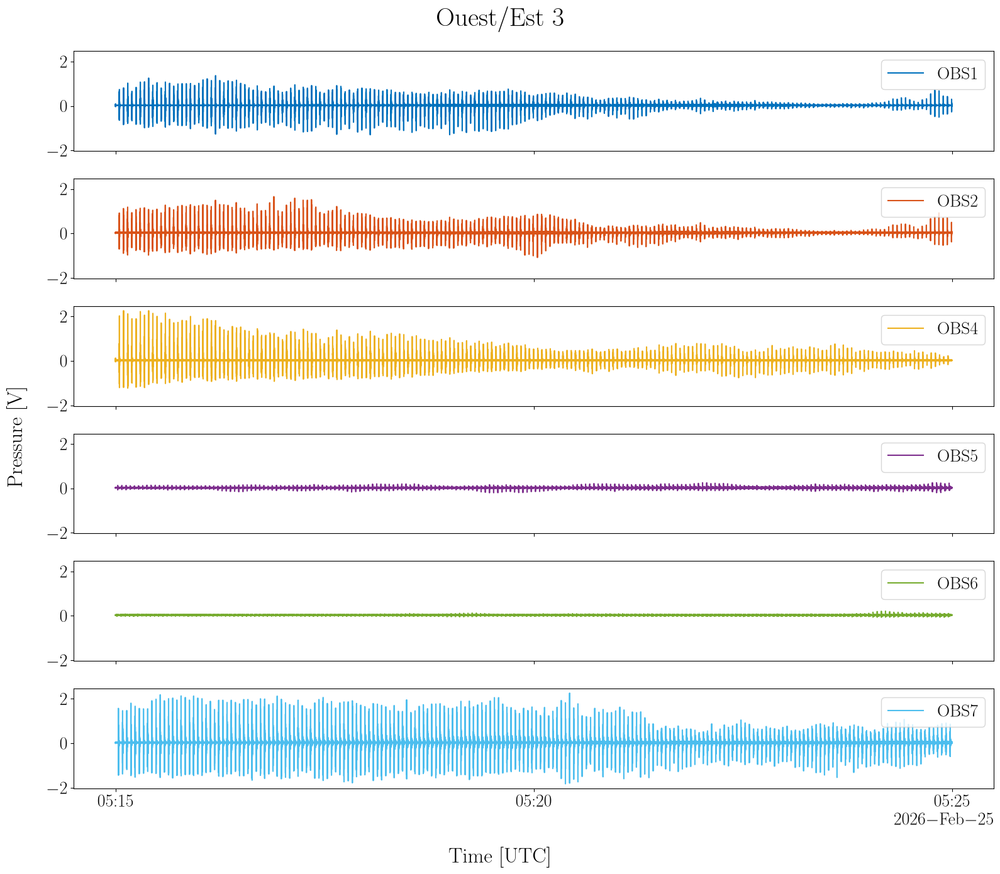

In [ ]:
# Plot 
single_fig = False
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    plt.show()

## Spectrogrames 

**Remarque** : l'amplitude des cannons décroit avec le temps avant de revenir à l'amplitude de départ. Ce comportement nominal des cannons à air comprimé se traduit par une modulation d'amplitude des tirs visibles sur les spectrogrames ci dessous.    

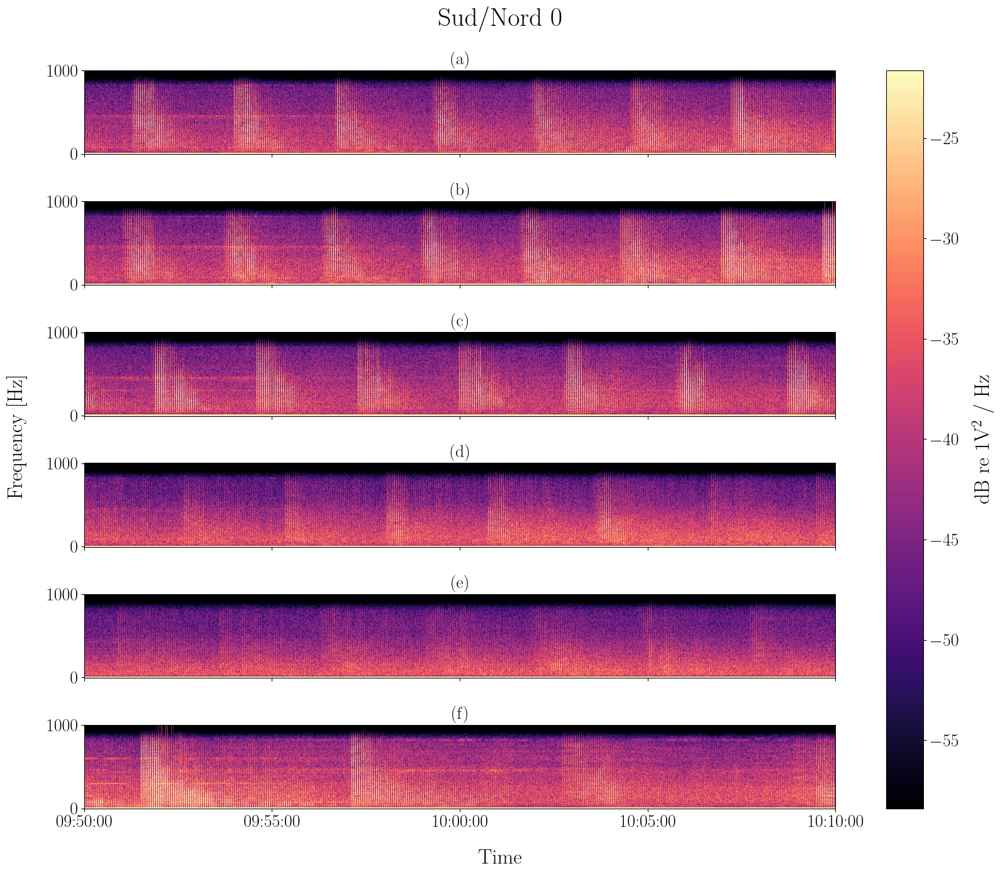

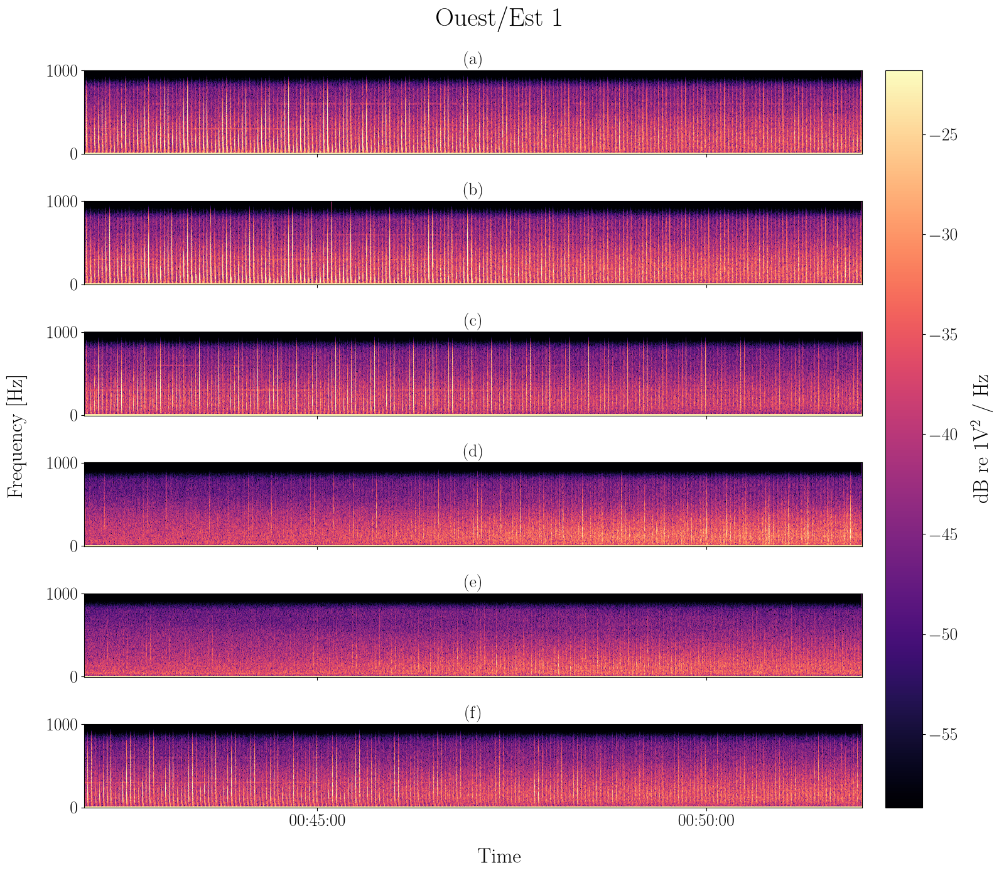

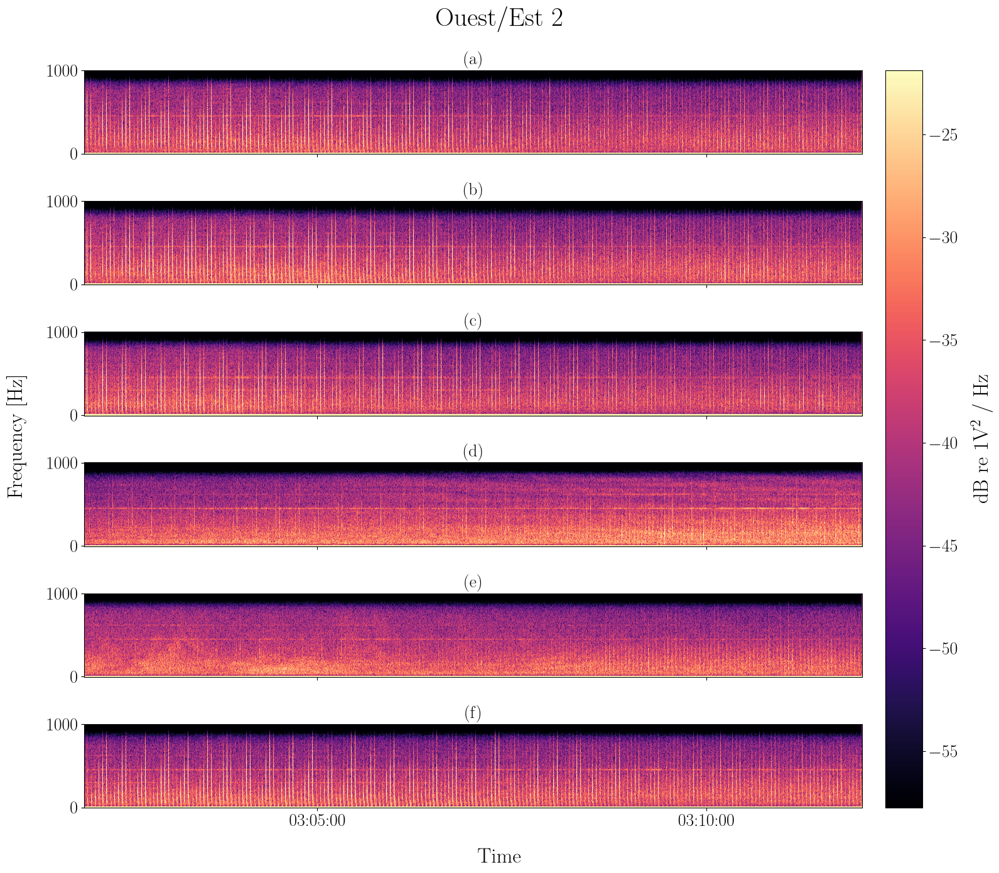

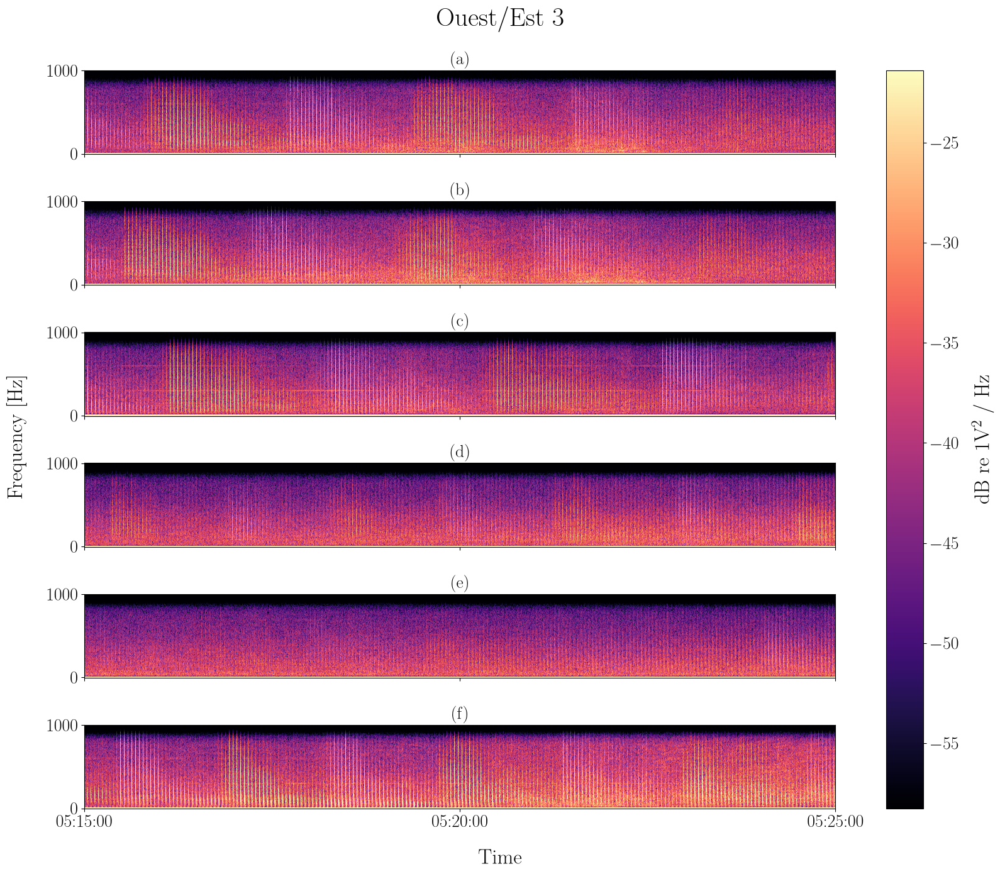

In [ ]:
# Plot 
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**8, noverlap=2**7, cmap="magma")
    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    plt.show()

# Calcul des grandeurs signantes 

In [ ]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                   ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:50...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 968B 2026-02-25T09:5...
│   │         * src_datetime           (src_datetime) datetime64[ns] 3kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 9kB ...
│   │           atl_lat                (atl_datetime) float64 9kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 509kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 3kB ...
│   │           tir_src_lon            (src_datetime) float64 3kB 5.957 5.957 ... 5.957
│   │           tir_src_lat            (src_datetime) float64 3kB 43.05 43.05 ... 43.02
│   │           tir_vessel_lon         (src_datetime) float64 3kB ...
│   │           tir_vessel_lat         (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 22kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                   ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:42...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 488B 2026-02-25T00:4...
│   │         * src_datetime           (src_datetime) datetime64[ns] 2kB 2026-02-25T00:42...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 5kB ...
│   │           atl_lat                (atl_datetime) float64 5kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 257kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 2kB ...
│   │           tir_src_lon            (src_datetime) float64 2kB 5.947 5.947 ... 5.966
│   │           tir_src_lat            (src_datetime) float64 2kB 43.03 43.03 ... 43.03
│   │           tir_vessel_lon         (src_datetime) float64 2kB ...
│   │           tir_vessel_lat         (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 11kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Ouest/Est
│   │           section_id:               1
│   ├── Group: /position/oe2
│   │   

## Extraction de chaques émissions

### Calcul de la célérité équivalente 

In [ ]:
celerity = xr.open_datatree(ACOUPLANE_CELERITY_NC_FPATH)
celerity

<xarray.DataTree>
Group: /
├── Group: /T0_00006
│       Dimensions:      (depth: 322)
│       Coordinates:
│         * depth        (depth) float64 3kB 0.0 0.6301 1.26 1.89 ... 198.8 199.4 200.0
│       Data variables:
│           temperature  (depth) float64 3kB ...
│           celerity     (depth) float64 3kB ...
│       Attributes:
│           longitude:                 5.9519785
│           latitude:                  43.0480848
│           surface_temperatude_degC:  14.2
│           pression_atmo_hPa:         1021.0
│           salinity_ppt:              37.5
├── Group: /T0_00007
│       Dimensions:      (depth: 253)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 156.2 156.8 157.4
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 5.9523738
│           latitude:                  43.0173035
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1020.2
│           salinity_ppt:              37.5
├── Group: /T0_00012
│       Dimensions:      (depth: 160)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 98.39 99.02 99.64
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 5.9512852
│           latitude:                  43.0566788
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1025.6
│           salinity_ppt:              37.5
├── Group: /T0_00020
│       Dimensions:      (depth: 233)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 143.8 144.4 145.0
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 6.2931097
│           latitude:                  42.9943315
│           surface_temperatude_degC:  14.1
│           pression_atmo_hPa:         1027.3
│           salinity_ppt:              37.5
├── Group: /T0_00021
│       Dimensions:      (depth: 111)
│       Coordinates:
│         * depth        (depth) float64 888B 0.0 0.6301 1.26 1.89 ... 67.8 68.42 69.05
│       Data variables:
│           temperature  (depth) float64 888B ...
│           celerity     (depth) float64 888B ...
│       Attributes:
│           longitude:                 6.269442
│           latitude:                  43.0373697
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1026.7
│           salinity_ppt:              37.5
├── Group: /T0_00022
│       Dimensions:      (depth: 144)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 88.41 89.04 89.66
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 6.2833635
│           latitude:                  43.058786
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1026.9
│           salinity_ppt:              37.4
...
├── Group: /T7_00011
│       Dimensions:      (depth: 836)
│       Coordinates:
│         * depth        (depth) float64 7kB 0.0 0.6472 1.294 ... 524.1 524.7 525.4
│       Data variables:
│           temperature  (depth) float64 7kB ...
│           celerity     (depth) float64 7kB ...
│       Attributes:
│           longitude:                 5.9700047
│           latitude:                  43.0205393
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1023.7
│           salinity_ppt:              37.5
├── Group: /T7_00013
│       Dimensions:      (depth: 561)
│       Coordinates:
│         * depth        (depth) float64 4kB 0.0 0.6472 1.294 ... 354.4 355.0 355.7
│       

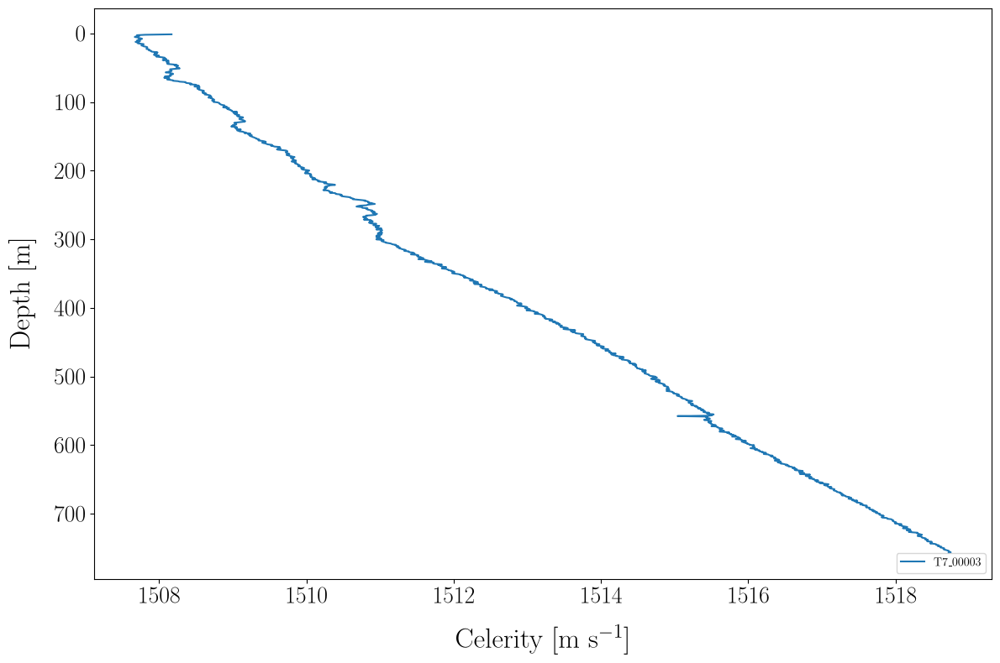

In [ ]:
selected_profile = "T7_00003"
# selected_profile = "T0_00020"

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
for name, node in celerity.children.items():
    if name == selected_profile:
        ds = node.to_dataset()
        ds.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)

    # ds = node.to_dataset()
    # ds.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)


# for ax in axs.flatten():
ax.legend(loc="lower right", ncols=2, fontsize=10)
# axs[1].legend(loc="upper right", ncols=2, fontsize=10)
# axs[1].set_ylabel("")

# plt.ylim(500, 0)

In [ ]:
ds_ = ds.sel(depth=slice(0, 100))
c_eq = equivalent_celerity(ds_.celerity.values, ds_.celerity.depth.values)
c_eq

np.float64(1508.1731018573482)

### Calcul des temps de propagation associés à chaque couple émission / récepteur 

In [ ]:
c0 = c_eq
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time 
    tps_propagation_s = dpropa_direct / c0 
    # tps_propagation_s = ds_pos_section.src_rcv_geodesic_dist / c0 
    ds_pos_section["tps_propagation_s"] = tps_propagation_s

    # Derive associated arrival dt 
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

In [ ]:
ds_pos_section.tps_propagation_s

<xarray.DataArray 'tps_propagation_s' (rcv_id: 7, src_datetime: 200)> Size: 11kB
array([[2.01927629, 2.01833359, 2.01740296, ..., 2.08237547, 2.08401844,
        2.08568942],
       [1.94676539, 1.94579036, 1.94482783, ..., 2.0124163 , 2.01411363,
        2.01583983],
       [2.02618961, 2.02747634, 2.0287747 , ..., 2.47977095, 2.4829856 ,
        2.48624016],
       ...,
       [9.22487567, 9.22173768, 9.21860136, ..., 8.64464875, 8.64197423,
        8.6392728 ],
       [1.52479395, 1.52066968, 1.51655084, ..., 0.90060091, 0.89901762,
        0.8974446 ],
       [1.5583739 , 1.55434158, 1.55031505, ..., 0.95683263, 0.95533801,
        0.95385333]], shape=(7, 200))
Coordinates:
  * rcv_id        (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs6' 'obs7' 'tlq'
  * src_datetime  (src_datetime) datetime64[ns] 2kB 2026-02-25T05:15:00.60009...
Attributes:
    units:      m
    long_name:  Immersion below MSL

In [ ]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                    ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:5...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 968B 2026-02-25T09:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 3kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 9kB ...
│   │           atl_lat                 (atl_datetime) float64 9kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 509kB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 3kB ...
│   │           tir_vessel_lon          (src_datetime) float64 3kB ...
│   │           tir_vessel_lat          (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 22kB 4.015e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 22kB 2.663 ... 2.458
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 22kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                    ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:4...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T00:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 2kB 2026-02-25T00:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 5kB ...
│   │           atl_lat                 (atl_datetime) float64 5kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 257kB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 2kB ...
│   │           tir_vessel_lon          (src_datetime) float64 2kB ...
│   │           tir_vessel_lat          (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 11kB 1.773e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 11kB 1.178 ... 1.773
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 11kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │      

In [ ]:
(portion.position.sn1.rcv_immersion, portion.position.sn1.rcv_id)

(<xarray.DataArray 'rcv_immersion' (rcv_id: 7)> Size: 14B
 array([ 119,  116,  118, 1077,  306,   93,   93], dtype=int16)
 Coordinates:
   * rcv_id   (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7' 'tlq'
 Attributes:
     units:      m
     long_name:  Immersion below MSL,
 <xarray.DataArray 'rcv_id' (rcv_id: 7)> Size: 112B
 array(['obs1', 'obs2', 'obs4', 'obs5', 'obs6', 'obs7', 'tlq'], dtype='<U4')
 Coordinates:
   * rcv_id   (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7' 'tlq')

### Comparaison aux signaux 

In [2]:
# r = ds_pos_section.src_rcv_geodesic_dist.max()
# delta_c = 10
# delta_t = (r*delta_c) / c0**2
# delta_t

c0 = 1508
delta_r = 200
delta_t = 1 / c0 * delta_r
delta_t


0.1326259946949602

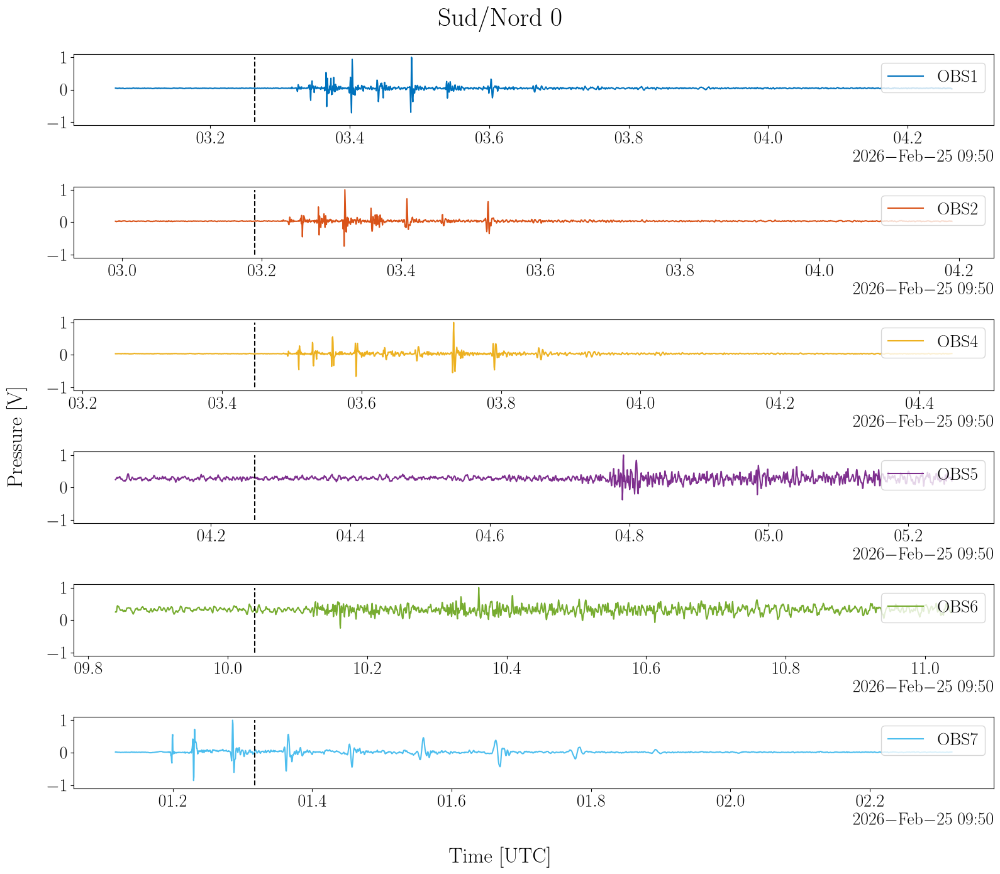

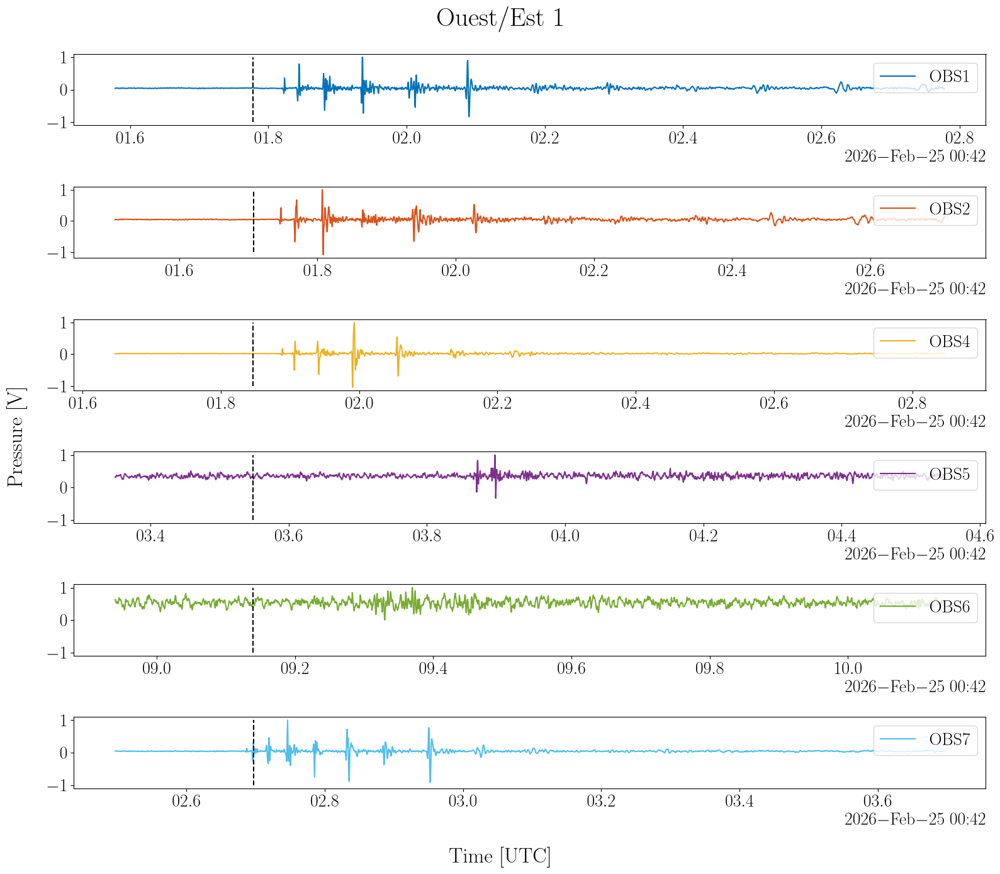

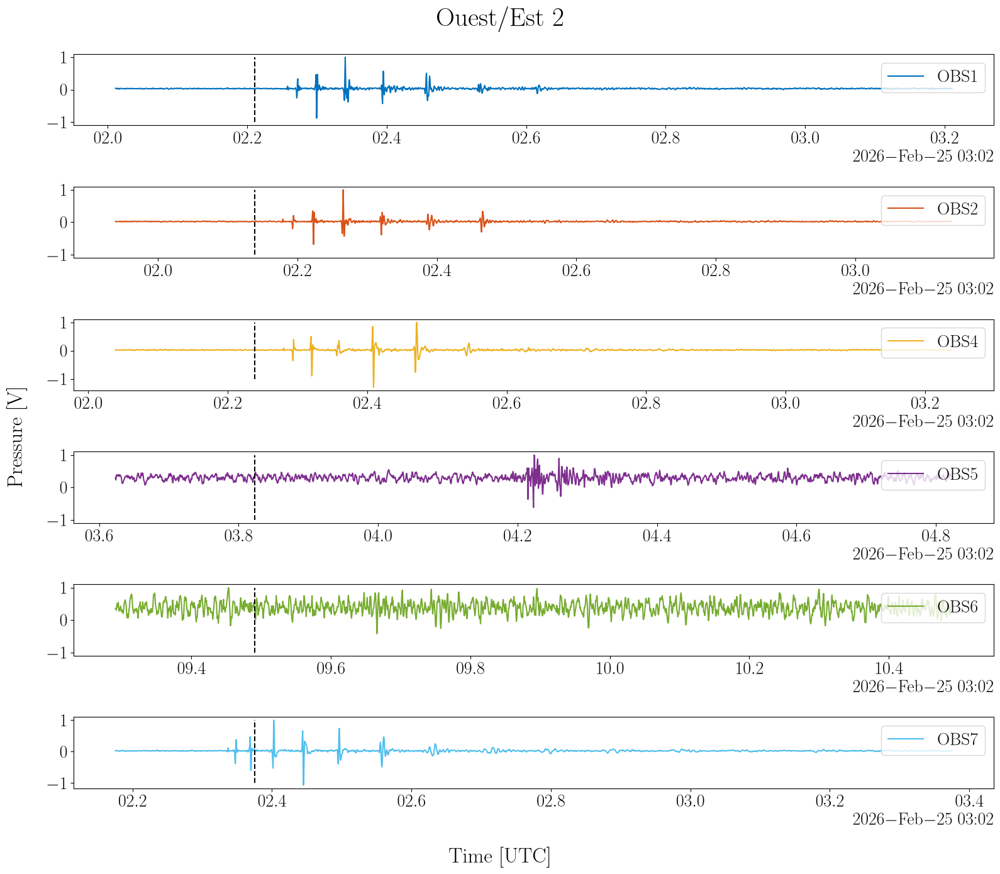

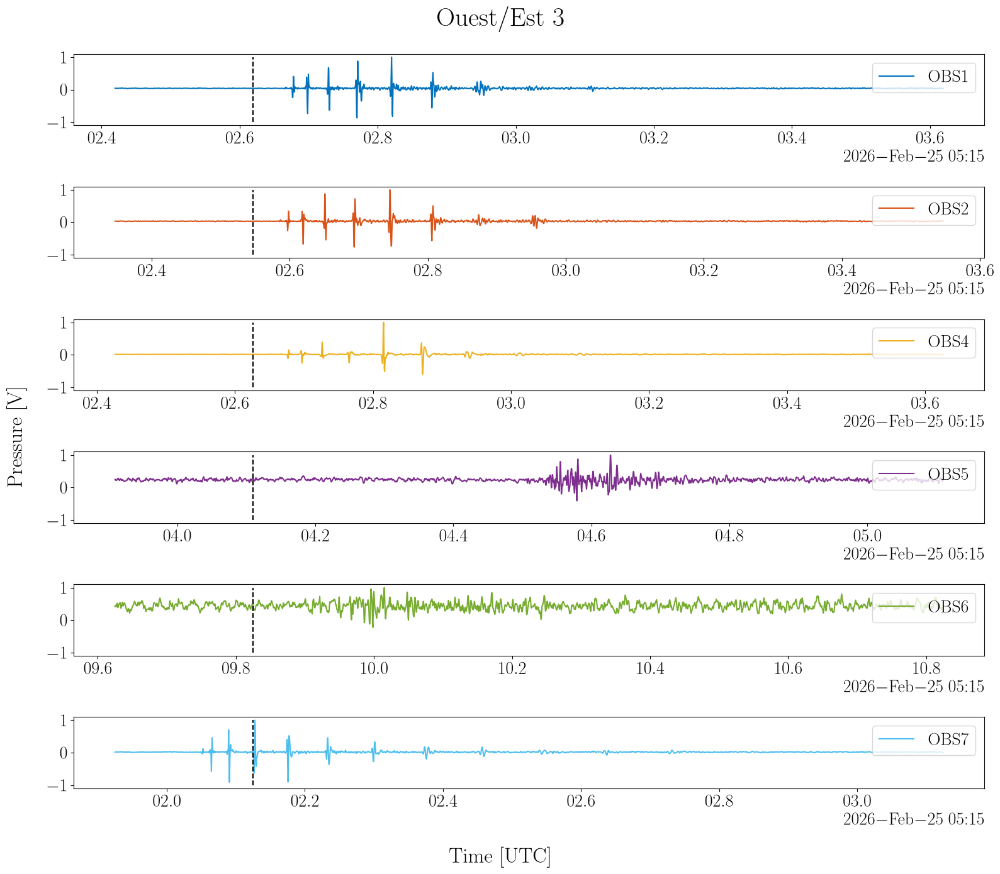

In [ ]:
nb_tir = 1
offset1 = 200
offset2 = 1000
obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
# obs_ids = obs_ids[[0, 3, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})
        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

### Découpage et calcul des grandeurs signantes 

In [ ]:
def compute_sxy_scot(
    ds_arr,
    signals,
    times,
    num_obs,
    den_obs,
    ref_obs=None,
    window_mode="common",
    fs=2000,
    offset_s=0.1,
    pulse_len_s=None,
    nfft=2**16,
    n_smooth=5,
):
    """Estimate the Sxy_scot = S_{num,den} / sqrt(S_{num,num} S_{den,den}) for each pulse.


    Parameters
    ----------
    ds_arr, signals, times, fs, offset_s, pulse_len_s, window_mode, ref_obs
        See `extract_pulse_windows`.
    num_obs : list of str
        Sensors in the numerator (e.g. [4, 1, 6]).
    den_obs : str
        Sensor in the denominator (e.g. 7).
    nfft : int
        FFT length (zero-padding if larger than the window).
    n_smooth : int
        Length of the moving average applied to the RTF magnitude in dB.

    Returns
    -------
    _type_
        _description_

    """

    all_obs = list(dict.fromkeys([*num_obs, den_obs, *(ref_obs or [])]))
    windows, idx_start = extract_pulse_windows(
        ds_arr,
        {o: signals[o] for o in all_obs},
        times,
        fs,
        offset_s,
        pulse_len_s,
        window_mode=window_mode,
        ref_obs=ref_obs,
    )

    # Remove last to avoid nan
    for o in all_obs:
        idx_start[o] = idx_start[o][:-1]
        windows[o] = windows[o][:-1]

    freq = np.fft.rfftfreq(nfft, d=1 / fs)
    fft = {o: np.fft.rfft(windows[o], n=nfft, axis=-1) for o in all_obs}

    # Auto-spectrums
    s_den = fft[den_obs] * np.conj(fft[den_obs])
    sxy_scot = np.stack(
        [
            (fft[o] * np.conj(fft[den_obs]))
            / (np.sqrt(s_den * fft[o] * np.conj(fft[o])) + 1e-12)
            for o in num_obs
        ]
    )

    # Compute
    # sxy = []
    cxy_ = []
    y = windows[den_obs]
    for o in num_obs:
        x = windows[o]
        n = x.shape[1]
        nfft = 2 * n - 1  # Zero pad to compute full correlation

        x_fft = np.fft.fft(x, n=nfft, axis=1)
        y_fft = np.fft.fft(y, n=nfft, axis=1)

        # # Sxy
        # sxy_o = x_fft * np.conj(y_fft)

        c_xy = np.fft.ifft(x_fft * np.conj(y_fft), axis=1)
        c_xy = np.real(c_xy)
        c_xy = np.fft.fftshift(c_xy, axes=1)
        # c_xy = sp.correlate(x, y, axis=1)

        cxy_.append(c_xy)

    tau = sp.correlation_lags(x.shape[1], y.shape[1], mode="full") * 1/fs
    cxy = np.stack(cxy_)
    

    rtf_id = [f"{o}/{den_obs}" for o in num_obs]
    dims = ("rtf_id", "pulse_id", "freq")
    return xr.Dataset(
        data_vars=dict(
            sxy_scot=(dims, sxy_scot),
            cxy=(("rtf_id", "pulse_id", "lag"), cxy),
            idx_start=(
                ("obs_id", "pulse_id"),
                np.stack([idx_start[o] for o in all_obs]),
            ),
        ),
        coords=dict(
            rtf_id=rtf_id,
            obs_id=all_obs,
            pulse_id=np.arange(windows[all_obs[0]].shape[0]),
            freq=freq,
            lag=tau,
        ),
        attrs=dict(
            fs=fs,
            offset_s=offset_s,
            nfft=nfft,
            den_obs=den_obs,
            window_mode=window_mode,
            n_smooth=n_smooth,
        ),
    )

In [ ]:
    # Compute cross spectrum S12 = X1 conj(X2)
    nfft = 2**16
    f_fft = np.fft.rfftfreq(nfft, d=1 / fs)
    fft_obs4 = np.fft.rfft(pulse_obs4, n=nfft)
    fft_obs7 = np.fft.rfft(pulse_obs7, n=nfft)
    sxy = fft_obs4 * np.conj(fft_obs7)
    syy = fft_obs7 * np.conj(fft_obs7)

    pi_xy = sxy / syy

NameError: name 'fs' is not defined